In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
USDA_PATH = "."

print("USDA files available:")
for file in os.listdir(USDA_PATH):
    print("-", file)

USDA files available:
- acquisition_samples.csv
- agricultural_samples.csv
- Download API Field Descriptions.xlsx
- eda.ipynb
- food.csv
- food_attribute.csv
- food_attribute_type.csv
- food_calorie_conversion_factor.csv
- food_category.csv
- food_component.csv
- food_nutrient.csv
- food_nutrient_conversion_factor.csv
- food_portion.csv
- food_protein_conversion_factor.csv
- food_update_log_entry.csv
- foundation_food.csv
- input_food.csv
- lab_method.csv
- lab_method_code.csv
- lab_method_nutrient.csv
- market_acquisition.csv
- measure_unit.csv
- nutrient.csv
- sample_food.csv
- sub_sample_food.csv
- sub_sample_result.csv


In [3]:
file_info = []

for file in os.listdir(USDA_PATH):
    file_path = os.path.join(USDA_PATH, file)

    if os.path.isfile(file_path):
        size_mb = os.path.getsize(file_path) / (1024**2)

        file_info.append({"file": file, "size_MB": round(size_mb, 2)})

file_info_df = (
    pd.DataFrame(file_info).sort_values("size_MB", ascending=False).reset_index(drop=True)
)

display(file_info_df)

,file,size_MB
0,food_nutrient.csv,9.62
1,food.csv,6.89
2,sub_sample_result.csv,5.05
3,food_update_log_entry.csv,4.99
4,sub_sample_food.csv,1.41
5,market_acquisition.csv,0.87
6,food_attribute.csv,0.72
7,food_portion.csv,0.68
8,input_food.csv,0.31
9,food_nutrient_conversion_factor.csv,0.19


In [5]:
food = pd.read_csv(os.path.join(USDA_PATH, "food.csv"))

print("Shape:", food.shape)
print("\nColumns:")
print(food.columns.tolist())

Shape: (87990, 5)

Columns:
['fdc_id', 'data_type', 'description', 'food_category_id', 'publication_date']


In [6]:
display(food.head())

,fdc_id,data_type,description,food_category_id,publication_date
0,319874,sample_food,"HUMMUS, SABRA CLASSIC",16.0,2019-04-01
1,319875,market_acquisition,"HUMMUS, SABRA CLASSIC",16.0,2019-04-01
2,319876,market_acquisition,"HUMMUS, SABRA CLASSIC",16.0,2019-04-01
3,319877,sub_sample_food,Hummus,16.0,2019-04-01
4,319878,sub_sample_food,Hummus,16.0,2019-04-01


In [7]:
food.info()

<class 'pandas.DataFrame'>
RangeIndex: 87990 entries, 0 to 87989
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   fdc_id            87990 non-null  int64  
 1   data_type         87990 non-null  str    
 2   description       87982 non-null  str    
 3   food_category_id  84179 non-null  float64
 4   publication_date  87990 non-null  str    
dtypes: float64(1), int64(1), str(3)
memory usage: 3.4 MB


In [8]:
food_missing = pd.DataFrame(
    {"missing_count": food.isnull().sum(), "missing_percentage": food.isnull().mean() * 100}
).sort_values("missing_percentage", ascending=False)

display(food_missing)

,missing_count,missing_percentage
food_category_id,3811,4.331174
description,8,0.009092
fdc_id,0,0.000000
data_type,0,0.000000
publication_date,0,0.000000


In [9]:
print("Duplicate rows:", food.duplicated().sum())

Duplicate rows: 0


In [10]:
id_columns = [col for col in food.columns if "id" in col.lower()]

print("Potential ID columns:")
print(id_columns)

Potential ID columns:
['fdc_id', 'food_category_id']


In [11]:
if "fdc_id" in food.columns:
    print("Total food records:", len(food))
    print("Unique FDC IDs:", food["fdc_id"].nunique())
    print("Duplicate FDC IDs:", food["fdc_id"].duplicated().sum())

Total food records: 87990
Unique FDC IDs: 87990
Duplicate FDC IDs: 0


In [12]:
if "description" in food.columns:
    display(food["description"].head(30).to_frame("food_description"))

,food_description
0,"HUMMUS, SABRA CLASSIC"
1,"HUMMUS, SABRA CLASSIC"
2,"HUMMUS, SABRA CLASSIC"
3,Hummus
4,Hummus
5,"HUMMUS, SABRA CLASSIC"
6,"HUMMUS, SABRA CLASSIC"
7,"HUMMUS, SABRA CLASSIC"
8,Hummus
9,Hummus


In [13]:
if "description" in food.columns:
    food_name_lengths = food["description"].fillna("").astype(str).str.len()

    print(food_name_lengths.describe())

count    87990.000000
mean        33.716911
std         19.039248
min          0.000000
25%         20.000000
50%         31.000000
75%         42.000000
max        128.000000
Name: description, dtype: float64


In [15]:
food_category = pd.read_csv(os.path.join(USDA_PATH, "food_category.csv"))

print("Shape:", food_category.shape)
print("\nColumns:")
print(food_category.columns.tolist())

display(food_category.head())

Shape: (28, 3)

Columns:
['id', 'code', 'description']


,id,code,description
0,1,100,Dairy and Egg Products
1,2,200,Spices and Herbs
2,3,300,Baby Foods
3,4,400,Fats and Oils
4,5,500,Poultry Products


In [16]:
food_category.info()

<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           28 non-null     int64
 1   code         28 non-null     int64
 2   description  28 non-null     str  
dtypes: int64(2), str(1)
memory usage: 804.0 bytes


In [17]:
display(
    pd.DataFrame(
        {
            "missing_count": food_category.isnull().sum(),
            "missing_percentage": food_category.isnull().mean() * 100,
        }
    )
)

,missing_count,missing_percentage
id,0,0.0
code,0,0.0
description,0,0.0


In [19]:
nutrient = pd.read_csv(os.path.join(USDA_PATH, "nutrient.csv"))

print("Shape:", nutrient.shape)
print("\nColumns:")
print(nutrient.columns.tolist())

display(nutrient.head())

Shape: (477, 5)

Columns:
['id', 'name', 'unit_name', 'nutrient_nbr', 'rank']


,id,name,unit_name,nutrient_nbr,rank
0,2047,Energy (Atwater General Factors),KCAL,957.0,280.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0,290.0
2,1001,Solids,G,201.0,200.0
3,1002,Nitrogen,G,202.0,500.0
4,1003,Protein,G,203.0,600.0


In [20]:
nutrient.info()

<class 'pandas.DataFrame'>
RangeIndex: 477 entries, 0 to 476
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            477 non-null    int64  
 1   name          477 non-null    str    
 2   unit_name     477 non-null    str    
 3   nutrient_nbr  465 non-null    float64
 4   rank          466 non-null    float64
dtypes: float64(2), int64(1), str(2)
memory usage: 18.8 KB


In [21]:
display(nutrient.head(50))

,id,name,unit_name,nutrient_nbr,rank
0,2047,Energy (Atwater General Factors),KCAL,957.0,280.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0,290.0
2,1001,Solids,G,201.0,200.0
3,1002,Nitrogen,G,202.0,500.0
4,1003,Protein,G,203.0,600.0
5,1004,Total lipid (fat),G,204.0,800.0
6,1005,"Carbohydrate, by difference",G,205.0,1110.0
7,1006,"Fiber, crude (DO NOT USE - Archived)",G,206.0,999999.0
8,1007,Ash,G,207.0,1000.0
9,1008,Energy,KCAL,208.0,300.0


In [22]:
[
    col
    for col in nutrient.columns
    if any(word in col.lower() for word in ["name", "nutrient", "unit"])
]

['name', 'unit_name', 'nutrient_nbr']

In [23]:
required_keywords = [
    "energy",
    "protein",
    "carbohydrate",
    "fat",
    "saturated",
    "fiber",
    "sugar",
    "sodium",
]

nutrient_matches = nutrient[
    nutrient["name"].astype(str).str.contains("|".join(required_keywords), case=False, na=False)
]

display(nutrient_matches)

,id,name,unit_name,nutrient_nbr,rank
0,2047,Energy (Atwater General Factors),KCAL,957.0,280.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0,290.0
4,1003,Protein,G,203.0,600.0
5,1004,Total lipid (fat),G,204.0,800.0
6,1005,"Carbohydrate, by difference",G,205.0,1110.0
7,1006,"Fiber, crude (DO NOT USE - Archived)",G,206.0,999999.0
9,1008,Energy,KCAL,208.0,300.0
50,1049,"Solids, non-fat",G,253.0,999999.0
51,1050,"Carbohydrate, by summation",G,205.2,1120.0
54,1053,Adjusted Protein,G,257.0,700.0


In [24]:
[
    col
    for col in nutrient.columns
    if any(word in col.lower() for word in ["name", "nutrient", "unit"])
]

['name', 'unit_name', 'nutrient_nbr']

In [25]:
print(food.shape)
print(food.columns.tolist())

(87990, 5)
['fdc_id', 'data_type', 'description', 'food_category_id', 'publication_date']


In [26]:
print(food_category.shape)
print(food_category.columns.tolist())

(28, 3)
['id', 'code', 'description']


In [27]:
print(nutrient.shape)
print(nutrient.columns.tolist())

(477, 5)
['id', 'name', 'unit_name', 'nutrient_nbr', 'rank']


In [28]:
[
    col
    for col in nutrient.columns
    if any(word in col.lower() for word in ["name", "nutrient", "unit"])
]

['name', 'unit_name', 'nutrient_nbr']

In [29]:
required_keywords = [
    "energy",
    "protein",
    "carbohydrate",
    "fat",
    "saturated",
    "fiber",
    "fibre",
    "sugar",
    "sodium",
]

nutrient_matches = nutrient[
    nutrient["name"].astype(str).str.contains("|".join(required_keywords), case=False, na=False)
].copy()

display(nutrient_matches[["id", "name", "unit_name", "nutrient_nbr", "rank"]].sort_values("name"))

,id,name,unit_name,nutrient_nbr,rank
54,1053,Adjusted Protein,G,257.0,700.0
6,1005,"Carbohydrate, by difference",G,205.0,1110.0
51,1050,"Carbohydrate, by summation",G,205.2,1120.0
73,1072,"Carbohydrate, other",G,284.0,NaN
450,2039,Carbohydrates,G,956.0,1100.0
63,1062,Energy,kJ,268.0,400.0
9,1008,Energy,KCAL,208.0,300.0
0,2047,Energy (Atwater General Factors),KCAL,957.0,280.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0,290.0
319,1319,"Fatty acids, monounsat., other",G,678.0,999999.0


In [30]:
target_nutrients = nutrient[
    nutrient["name"]
    .astype(str)
    .str.contains(
        "Energy|Protein|Carbohydrate|Total lipid|Saturated|Fiber|Fibre|Sugars|Sodium",
        case=False,
        na=False,
        regex=True,
    )
].copy()

display(target_nutrients[["id", "name", "unit_name", "nutrient_nbr"]])

,id,name,unit_name,nutrient_nbr
0,2047,Energy (Atwater General Factors),KCAL,957.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0
4,1003,Protein,G,203.0
5,1004,Total lipid (fat),G,204.0
6,1005,"Carbohydrate, by difference",G,205.0
7,1006,"Fiber, crude (DO NOT USE - Archived)",G,206.0
9,1008,Energy,KCAL,208.0
51,1050,"Carbohydrate, by summation",G,205.2
54,1053,Adjusted Protein,G,257.0
63,1062,Energy,kJ,268.0


In [31]:
energy_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("energy", case=False, na=False)
]

display(energy_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
0,2047,Energy (Atwater General Factors),KCAL,957.0,280.0
1,2048,Energy (Atwater Specific Factors),KCAL,958.0,290.0
9,1008,Energy,KCAL,208.0,300.0
63,1062,Energy,kJ,268.0,400.0


In [32]:
protein_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("protein", case=False, na=False)
]

display(protein_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
4,1003,Protein,G,203.0,600.0
54,1053,Adjusted Protein,G,257.0,700.0


In [33]:
carb_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("carbohydrate", case=False, na=False)
]

display(carb_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
6,1005,"Carbohydrate, by difference",G,205.0,1110.0
51,1050,"Carbohydrate, by summation",G,205.2,1120.0
73,1072,"Carbohydrate, other",G,284.0,NaN
450,2039,Carbohydrates,G,956.0,1100.0


In [34]:
fat_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("fat|lipid", case=False, na=False)
]

display(fat_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]].head(50))

,id,name,unit_name,nutrient_nbr,rank
5,1004,Total lipid (fat),G,204.0,800.0
50,1049,"Solids, non-fat",G,253.0,999999.0
86,1085,Total fat (NLEA),G,298.0,900.0
256,1255,Phospholipids,G,603.0,999999.0
257,1256,Glycolipids,G,604.0,999999.0
258,1257,"Fatty acids, total trans",G,605.0,15400.0
259,1258,"Fatty acids, total saturated",G,606.0,9700.0
290,1290,Unsaponifiable matter (lipids),G,643.0,999999.0
291,1291,"Fatty acids, other than 607-615, 617-621, 624-632, 652-654, 686-689)",G,644.0,999999.0
292,1292,"Fatty acids, total monounsaturated",G,645.0,11400.0


In [35]:
fiber_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("fiber|fibre", case=False, na=False)
]

display(fiber_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
7,1006,"Fiber, crude (DO NOT USE - Archived)",G,206.0,999999.0
67,1066,"Fiber, neutral detergent (DO NOT USE - Archived)",G,273.0,999999.0
80,1079,"Fiber, total dietary",G,291.0,1200.0
83,1082,"Fiber, soluble",G,295.0,1240.0
85,1084,"Fiber, insoluble",G,297.0,1260.0
444,2033,Total dietary fiber (AOAC 2011.25),G,293.0,1300.0
445,2034,Insoluble dietary fiber (IDF),G,293.1,1310.0
446,2035,Soluble dietary fiber (SDFP+SDFS),G,293.2,1320.0
447,2036,Soluble dietary fiber (SDFP),G,954.0,1324.0
448,2037,Soluble dietary fiber (SDFS),G,953.0,1326.0


In [36]:
sugar_nutrients = nutrient[nutrient["name"].astype(str).str.contains("sugar", case=False, na=False)]

display(sugar_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
64,1063,"Sugars, Total",G,269.3,1500.0
68,1067,Reducing sugars,G,274.0,999999.0
87,1086,Total sugar alcohols,G,299.0,999999.0
236,1235,"Sugars, added",G,539.0,1540.0
237,1236,"Sugars, intrinsic",G,549.0,1520.0
415,2000,Total Sugars,G,269.0,1510.0


In [37]:
sodium_nutrients = nutrient[
    nutrient["name"].astype(str).str.contains("sodium", case=False, na=False)
]

display(sodium_nutrients[["id", "name", "unit_name", "nutrient_nbr", "rank"]])

,id,name,unit_name,nutrient_nbr,rank
94,1093,"Sodium, Na",MG,307.0,5800.0


In [38]:
food_nutrient = pd.read_csv(os.path.join(USDA_PATH, "food_nutrient.csv"))

print("Shape:", food_nutrient.shape)

print("\nColumns:")
print(food_nutrient.columns.tolist())

Shape: (170469, 11)

Columns:
['id', 'fdc_id', 'nutrient_id', 'amount', 'data_points', 'derivation_id', 'min', 'max', 'median', 'footnote', 'min_year_acquired']


C:\Users\venka\AppData\Local\Temp\ipykernel_30880\2806245002.py:1: DtypeWarning: Columns (0: footnote) have mixed types. Specify dtype option on import or set low_memory=False.
  food_nutrient = pd.read_csv(


In [39]:
food_nutrient.info()

<class 'pandas.DataFrame'>
RangeIndex: 170469 entries, 0 to 170468
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 170469 non-null  int64  
 1   fdc_id             170469 non-null  int64  
 2   nutrient_id        170469 non-null  int64  
 3   amount             170436 non-null  float64
 4   data_points        166818 non-null  float64
 5   derivation_id      170038 non-null  float64
 6   min                17581 non-null   float64
 7   max                17581 non-null   float64
 8   median             18183 non-null   float64
 9   footnote           22 non-null      str    
 10  min_year_acquired  32298 non-null   float64
dtypes: float64(7), int64(3), str(1)
memory usage: 14.3 MB


In [40]:
display(food_nutrient.head())

,id,fdc_id,nutrient_id,amount,data_points,derivation_id,min,max,median,footnote,min_year_acquired
0,2201847,319877,1051,56.30,1.0,1.0,NaN,NaN,NaN,NaN,NaN
1,2201845,319877,1002,1.28,1.0,1.0,NaN,NaN,NaN,NaN,NaN
2,2201846,319877,1004,19.00,1.0,1.0,NaN,NaN,NaN,NaN,NaN
3,2201844,319877,1007,1.98,1.0,1.0,NaN,NaN,NaN,NaN,NaN
4,2201852,319878,1091,188.00,1.0,1.0,NaN,NaN,NaN,NaN,NaN


In [41]:
food_nutrient_missing = pd.DataFrame(
    {
        "missing_count": food_nutrient.isnull().sum(),
        "missing_percentage": food_nutrient.isnull().mean() * 100,
    }
).sort_values("missing_percentage", ascending=False)

display(food_nutrient_missing)

,missing_count,missing_percentage
footnote,170447,99.987094
min,152888,89.686688
max,152888,89.686688
median,152286,89.333545
min_year_acquired,138171,81.053447
data_points,3651,2.141738
derivation_id,431,0.252832
amount,33,0.019358
nutrient_id,0,0.000000
id,0,0.000000


In [42]:
[
    col
    for col in food_nutrient.columns
    if any(word in col.lower() for word in ["fdc", "nutrient", "amount", "unit", "food"])
]

['fdc_id', 'nutrient_id', 'amount']

In [43]:
print("Unique food IDs in food_nutrient:", food_nutrient["fdc_id"].nunique())

print("Unique nutrient IDs in food_nutrient:", food_nutrient["nutrient_id"].nunique())

Unique food IDs in food_nutrient: 76036
Unique nutrient IDs in food_nutrient: 235


In [44]:
known_nutrient_ids = set(nutrient["id"])

used_nutrient_ids = set(food_nutrient["nutrient_id"].dropna())

unknown_ids = used_nutrient_ids - known_nutrient_ids

print("Nutrient IDs used in food_nutrient:", len(used_nutrient_ids))

print(
    "Nutrient IDs found in nutrient table:", len(used_nutrient_ids.intersection(known_nutrient_ids))
)

print("Unknown nutrient IDs:", len(unknown_ids))

Nutrient IDs used in food_nutrient: 235
Nutrient IDs found in nutrient table: 234
Unknown nutrient IDs: 1


In [45]:
known_food_ids = set(food["fdc_id"])

used_food_ids = set(food_nutrient["fdc_id"].dropna())

unknown_food_ids = used_food_ids - known_food_ids

print("Food IDs in food_nutrient:", len(used_food_ids))

print("Food IDs found in food table:", len(used_food_ids.intersection(known_food_ids)))

print("Unknown food IDs:", len(unknown_food_ids))

Food IDs in food_nutrient: 76036
Food IDs found in food table: 76036
Unknown food IDs: 0


In [46]:
required_nutrient_ids = {
    "calories": 1008,
    "protein": 1003,
    "carbohydrates": 1005,
    "total_fat": 1004,
    "saturated_fat": 1258,
    "fibre": 1079,
    "sugar": 1063,
    "sodium": 1093,
}

required_nutrient_ids

{'calories': 1008,
 'protein': 1003,
 'carbohydrates': 1005,
 'total_fat': 1004,
 'saturated_fat': 1258,
 'fibre': 1079,
 'sugar': 1063,
 'sodium': 1093}

In [47]:
selected_nutrients = nutrient[nutrient["id"].isin(required_nutrient_ids.values())][
    ["id", "name", "unit_name", "nutrient_nbr", "rank"]
].sort_values("id")

display(selected_nutrients)

,id,name,unit_name,nutrient_nbr,rank
4,1003,Protein,G,203.0,600.0
5,1004,Total lipid (fat),G,204.0,800.0
6,1005,"Carbohydrate, by difference",G,205.0,1110.0
9,1008,Energy,KCAL,208.0,300.0
64,1063,"Sugars, Total",G,269.3,1500.0
80,1079,"Fiber, total dietary",G,291.0,1200.0
94,1093,"Sodium, Na",MG,307.0,5800.0
259,1258,"Fatty acids, total saturated",G,606.0,9700.0


In [48]:
usda_required_nutrients = food_nutrient[
    food_nutrient["nutrient_id"].isin(required_nutrient_ids.values())
].copy()

print("Rows containing our required nutrients:", len(usda_required_nutrients))

display(usda_required_nutrients.head())

Rows containing our required nutrients: 14272


,id,fdc_id,nutrient_id,amount,data_points,derivation_id,min,max,median,footnote,min_year_acquired
2,2201846,319877,1004,19.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN
8,2201854,319878,1093,446.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN
16,2201859,319882,1004,18.7,1.0,1.0,NaN,NaN,NaN,NaN,NaN
19,2201862,319884,1093,444.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN
28,2201873,319892,1004,16.6,1.0,1.0,NaN,NaN,NaN,NaN,NaN


In [49]:
print(food_nutrient.shape)
print(food_nutrient.columns.tolist())

(170469, 11)
['id', 'fdc_id', 'nutrient_id', 'amount', 'data_points', 'derivation_id', 'min', 'max', 'median', 'footnote', 'min_year_acquired']


In [50]:
display(food_nutrient.head())

,id,fdc_id,nutrient_id,amount,data_points,derivation_id,min,max,median,footnote,min_year_acquired
0,2201847,319877,1051,56.30,1.0,1.0,NaN,NaN,NaN,NaN,NaN
1,2201845,319877,1002,1.28,1.0,1.0,NaN,NaN,NaN,NaN,NaN
2,2201846,319877,1004,19.00,1.0,1.0,NaN,NaN,NaN,NaN,NaN
3,2201844,319877,1007,1.98,1.0,1.0,NaN,NaN,NaN,NaN,NaN
4,2201852,319878,1091,188.00,1.0,1.0,NaN,NaN,NaN,NaN,NaN


In [51]:
# Join food_nutrient with nutrient definitions
food_nutrient_named = food_nutrient.merge(
    nutrient[["id", "name", "unit_name"]],
    left_on="nutrient_id",
    right_on="id",
    how="left",
    suffixes=("", "_nutrient"),
)

print("Shape:", food_nutrient_named.shape)

display(food_nutrient_named[["fdc_id", "nutrient_id", "name", "unit_name", "amount"]].head(20))

Shape: (170469, 14)


,fdc_id,nutrient_id,name,unit_name,amount
0,319877,1051,Water,G,56.30
1,319877,1002,Nitrogen,G,1.28
2,319877,1004,Total lipid (fat),G,19.00
3,319877,1007,Ash,G,1.98
4,319878,1091,"Phosphorus, P",MG,188.00
5,319878,1101,"Manganese, Mn",MG,1.21
6,319878,1092,"Potassium, K",MG,326.00
7,319878,1087,"Calcium, Ca",MG,46.00
8,319878,1093,"Sodium, Na",MG,446.00
9,319878,1090,"Magnesium, Mg",MG,75.90


In [52]:
usda_nutrition = food_nutrient_named[
    food_nutrient_named["nutrient_id"].isin(required_nutrient_ids.values())
].copy()

print("Rows:", len(usda_nutrition))
print("Foods:", usda_nutrition["fdc_id"].nunique())

display(usda_nutrition[["fdc_id", "nutrient_id", "name", "unit_name", "amount"]].head(20))

Rows: 14272
Foods: 10664


,fdc_id,nutrient_id,name,unit_name,amount
2,319877,1004,Total lipid (fat),G,19.0
8,319878,1093,"Sodium, Na",MG,446.0
16,319882,1004,Total lipid (fat),G,18.7
19,319884,1093,"Sodium, Na",MG,444.0
28,319892,1004,Total lipid (fat),G,16.6
31,319893,1093,"Sodium, Na",MG,387.0
43,319899,1004,Total lipid (fat),G,19.1
50,319900,1093,"Sodium, Na",MG,489.0
97,319908,1004,Total lipid (fat),G,18.2
107,319912,1093,"Sodium, Na",MG,428.0


In [53]:
nutrient_coverage = (
    usda_nutrition.groupby(["nutrient_id", "name", "unit_name"])
    .agg(food_count=("fdc_id", "nunique"), value_count=("amount", "count"))
    .reset_index()
    .sort_values("food_count", ascending=False)
)

display(nutrient_coverage)

,nutrient_id,name,unit_name,food_count,value_count
1,1004,Total lipid (fat),G,4756,4756
6,1093,"Sodium, Na",MG,3856,3856
5,1079,"Fiber, total dietary",G,2472,2472
0,1003,Protein,G,1410,1410
7,1258,"Fatty acids, total saturated",G,986,986
2,1005,"Carbohydrate, by difference",G,377,377
4,1063,"Sugars, Total",G,280,280
3,1008,Energy,KCAL,135,135


In [54]:
total_usda_foods = food["fdc_id"].nunique()

nutrient_coverage["coverage_percentage"] = nutrient_coverage["food_count"] / total_usda_foods * 100

display(nutrient_coverage)

,nutrient_id,name,unit_name,food_count,value_count,coverage_percentage
1,1004,Total lipid (fat),G,4756,4756,5.405160
6,1093,"Sodium, Na",MG,3856,3856,4.382316
5,1079,"Fiber, total dietary",G,2472,2472,2.809410
0,1003,Protein,G,1410,1410,1.602455
7,1258,"Fatty acids, total saturated",G,986,986,1.120582
2,1005,"Carbohydrate, by difference",G,377,377,0.428458
4,1063,"Sugars, Total",G,280,280,0.318218
3,1008,Energy,KCAL,135,135,0.153427


In [55]:
nutrient_name_map = {
    1008: "calories",
    1003: "protein",
    1005: "carbohydrates",
    1004: "total_fat",
    1258: "saturated_fat",
    1079: "fibre",
    1063: "sugar",
    1093: "sodium",
}

usda_nutrition["nutrition_field"] = usda_nutrition["nutrient_id"].map(nutrient_name_map)

display(usda_nutrition[["fdc_id", "nutrition_field", "name", "unit_name", "amount"]].head(20))

,fdc_id,nutrition_field,name,unit_name,amount
2,319877,total_fat,Total lipid (fat),G,19.0
8,319878,sodium,"Sodium, Na",MG,446.0
16,319882,total_fat,Total lipid (fat),G,18.7
19,319884,sodium,"Sodium, Na",MG,444.0
28,319892,total_fat,Total lipid (fat),G,16.6
31,319893,sodium,"Sodium, Na",MG,387.0
43,319899,total_fat,Total lipid (fat),G,19.1
50,319900,sodium,"Sodium, Na",MG,489.0
97,319908,total_fat,Total lipid (fat),G,18.2
107,319912,sodium,"Sodium, Na",MG,428.0


In [56]:
usda_nutrition_wide = usda_nutrition.pivot_table(
    index="fdc_id", columns="nutrition_field", values="amount", aggfunc="first"
).reset_index()

usda_nutrition_wide.columns.name = None

print("Shape:", usda_nutrition_wide.shape)

display(usda_nutrition_wide.head())

Shape: (10664, 9)


,fdc_id,calories,carbohydrates,fibre,protein,saturated_fat,sodium,sugar,total_fat
0,319877,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.0
1,319878,NaN,NaN,NaN,NaN,NaN,446.0,NaN,NaN
2,319882,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.7
3,319884,NaN,NaN,NaN,NaN,NaN,444.0,NaN,NaN
4,319892,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.6


In [57]:
usda_nutrition_wide = usda_nutrition_wide.merge(
    food[["fdc_id", "description", "data_type", "food_category_id"]], on="fdc_id", how="left"
)

print("Shape:", usda_nutrition_wide.shape)

display(usda_nutrition_wide.head())

Shape: (10664, 12)


,fdc_id,calories,carbohydrates,fibre,protein,saturated_fat,sodium,sugar,total_fat,description,data_type,food_category_id
0,319877,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.0,Hummus,sub_sample_food,16.0
1,319878,NaN,NaN,NaN,NaN,NaN,446.0,NaN,NaN,Hummus,sub_sample_food,16.0
2,319882,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.7,Hummus,sub_sample_food,16.0
3,319884,NaN,NaN,NaN,NaN,NaN,444.0,NaN,NaN,Hummus,sub_sample_food,16.0
4,319892,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.6,Hummus,sub_sample_food,16.0


In [58]:
nutrition_columns_usda = [
    "calories",
    "protein",
    "carbohydrates",
    "total_fat",
    "saturated_fat",
    "fibre",
    "sugar",
    "sodium",
]

usda_nutrition_wide = usda_nutrition_wide[
    [
        "fdc_id",
        "description",
        "data_type",
        "food_category_id",
        *nutrition_columns_usda,
    ]
]

display(usda_nutrition_wide.head())

,fdc_id,description,data_type,food_category_id,calories,protein,carbohydrates,total_fat,saturated_fat,fibre,sugar,sodium
0,319877,Hummus,sub_sample_food,16.0,NaN,NaN,NaN,19.0,NaN,NaN,NaN,NaN
1,319878,Hummus,sub_sample_food,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,446.0
2,319882,Hummus,sub_sample_food,16.0,NaN,NaN,NaN,18.7,NaN,NaN,NaN,NaN
3,319884,Hummus,sub_sample_food,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,444.0
4,319892,Hummus,sub_sample_food,16.0,NaN,NaN,NaN,16.6,NaN,NaN,NaN,NaN


In [59]:
usda_missing = pd.DataFrame(
    {
        "missing_count": usda_nutrition_wide[nutrition_columns_usda].isnull().sum(),
        "missing_percentage": (usda_nutrition_wide[nutrition_columns_usda].isnull().mean() * 100),
    }
)

display(usda_missing)

,missing_count,missing_percentage
calories,10529,98.734059
protein,9254,86.777944
carbohydrates,10287,96.464741
total_fat,5908,55.401350
saturated_fat,9678,90.753938
fibre,8192,76.819205
sugar,10384,97.374344
sodium,6808,63.840960


In [60]:
usda_nutrition_summary = usda_nutrition_wide[nutrition_columns_usda].describe().T

display(usda_nutrition_summary)

,count,mean,std,min,25%,50%,75%,max
calories,135.0,194.120370,165.645900,12.000,52.500000,148.000,327.000000,833.00
protein,1410.0,19.618496,8.875469,0.000,18.429688,23.300,24.900000,79.90
carbohydrates,377.0,17.709922,24.417407,-0.705,2.440000,7.137,19.292275,99.60
total_fat,4756.0,8.403509,15.246670,0.000,0.400000,1.350,7.207500,99.40
saturated_fat,986.0,7.977765,8.317785,0.000,1.162500,5.555,13.937500,82.50
fibre,2472.0,4.025694,3.765654,0.000,2.042250,3.900,4.400000,43.94
sugar,280.0,7.064473,12.151779,0.000,2.242000,3.330,8.049250,99.80
sodium,3856.0,512.357508,3183.451842,0.000,0.000000,39.800,266.250000,40700.00


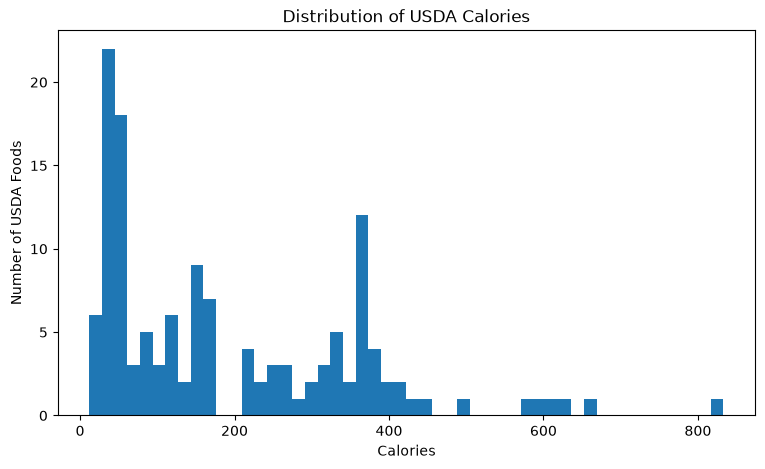

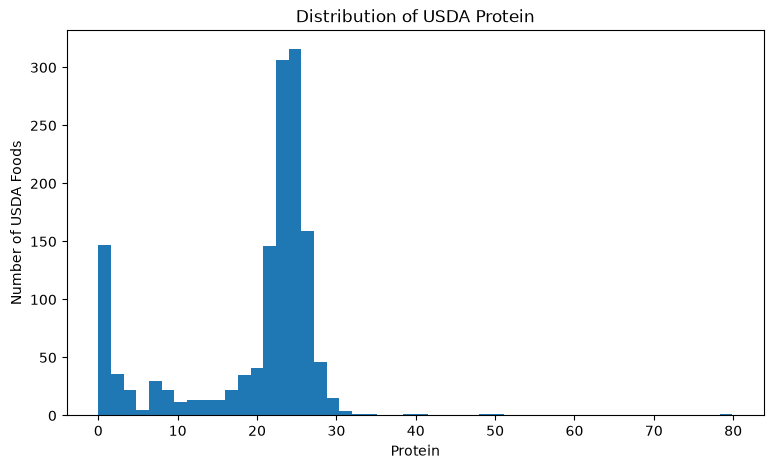

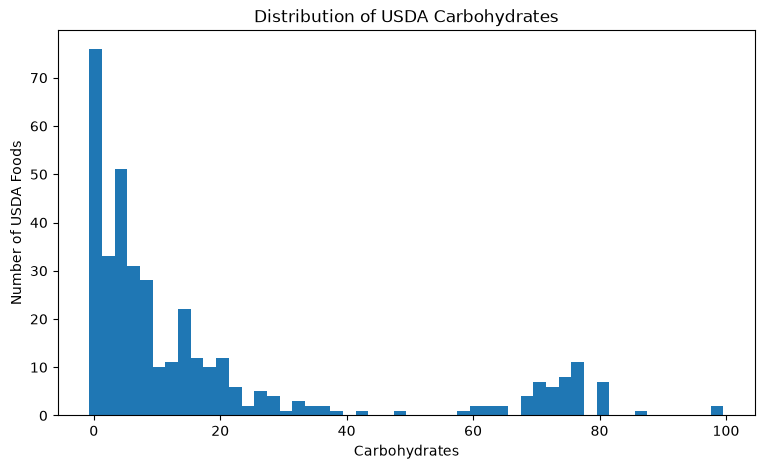

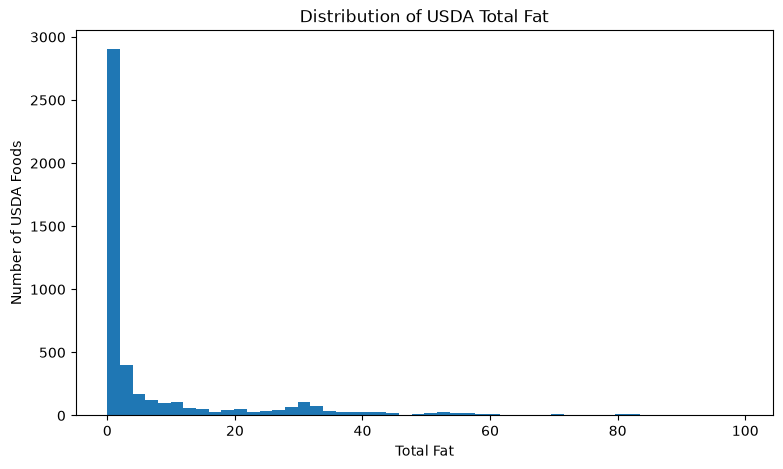

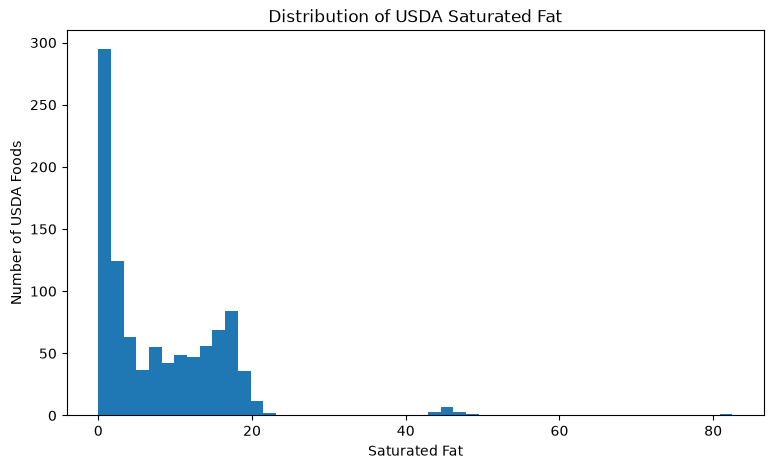

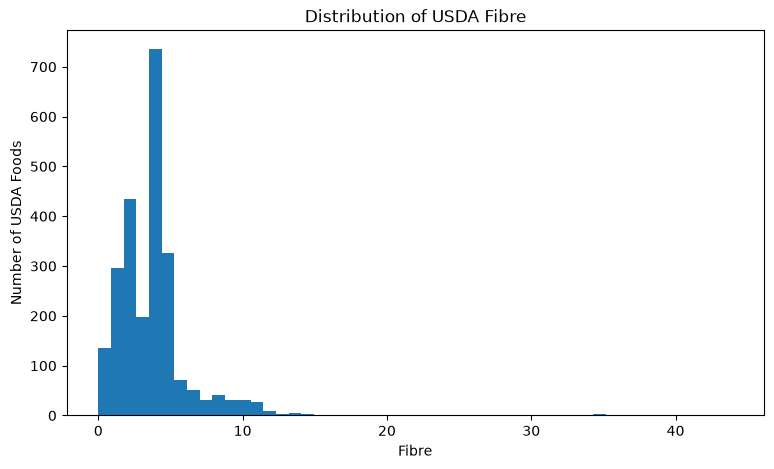

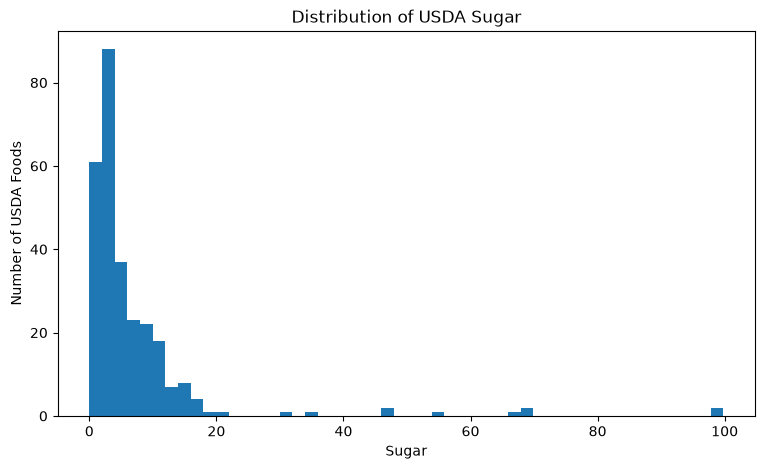

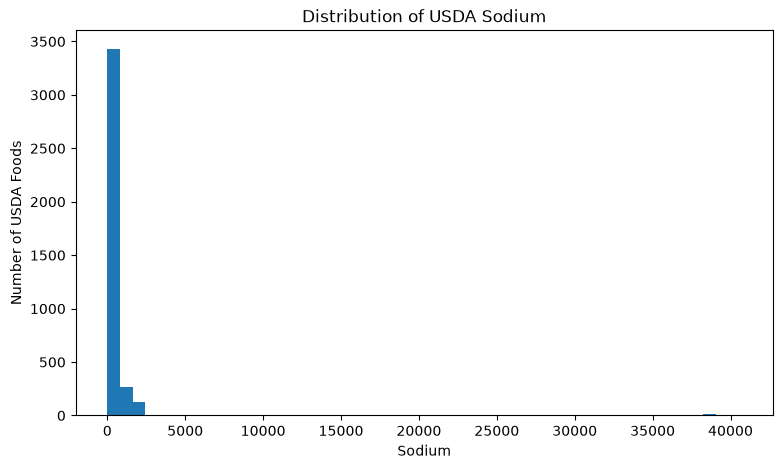

In [61]:
for column in nutrition_columns_usda:
    plt.figure(figsize=(9, 5))

    plt.hist(usda_nutrition_wide[column].dropna(), bins=50)

    plt.xlabel(column.replace("_", " ").title())
    plt.ylabel("Number of USDA Foods")
    plt.title(f"Distribution of USDA {column.replace('_', ' ').title()}")

    plt.show()

In [62]:
usda_zero_summary = pd.DataFrame(
    {
        "zero_count": (usda_nutrition_wide[nutrition_columns_usda] == 0).sum(),
        "zero_percentage": ((usda_nutrition_wide[nutrition_columns_usda] == 0).mean() * 100),
    }
)

display(usda_zero_summary)

,zero_count,zero_percentage
calories,0,0.000000
protein,5,0.046887
carbohydrates,36,0.337584
total_fat,128,1.200300
saturated_fat,5,0.046887
fibre,87,0.815829
sugar,6,0.056264
sodium,1039,9.743061


In [63]:
print("=" * 70)
print("USDA FOUNDATION FOODS — NUTRITION EDA SUMMARY")
print("=" * 70)

print(f"\nTotal USDA food records:       {food['fdc_id'].nunique():,}")
print(f"Foods with nutrient records:   {food_nutrient['fdc_id'].nunique():,}")
print(f"Required nutrient rows:        {len(usda_nutrition):,}")
print(f"Final nutrition food records:  {len(usda_nutrition_wide):,}")

print("\nNutrition fields:")
for column in nutrition_columns_usda:
    print(f"- {column}")

print("\nFinal table shape:")
print(usda_nutrition_wide.shape)

print("=" * 70)

USDA FOUNDATION FOODS — NUTRITION EDA SUMMARY

Total USDA food records:       87,990
Foods with nutrient records:   76,036
Required nutrient rows:        14,272
Final nutrition food records:  10,664

Nutrition fields:
- calories
- protein
- carbohydrates
- total_fat
- saturated_fat
- fibre
- sugar
- sodium

Final table shape:
(10664, 12)


In [64]:
display(nutrient_coverage)

,nutrient_id,name,unit_name,food_count,value_count,coverage_percentage
1,1004,Total lipid (fat),G,4756,4756,5.405160
6,1093,"Sodium, Na",MG,3856,3856,4.382316
5,1079,"Fiber, total dietary",G,2472,2472,2.809410
0,1003,Protein,G,1410,1410,1.602455
7,1258,"Fatty acids, total saturated",G,986,986,1.120582
2,1005,"Carbohydrate, by difference",G,377,377,0.428458
4,1063,"Sugars, Total",G,280,280,0.318218
3,1008,Energy,KCAL,135,135,0.153427


In [66]:
display(usda_missing)

,missing_count,missing_percentage
calories,10529,98.734059
protein,9254,86.777944
carbohydrates,10287,96.464741
total_fat,5908,55.401350
saturated_fat,9678,90.753938
fibre,8192,76.819205
sugar,10384,97.374344
sodium,6808,63.840960


In [67]:
display(usda_nutrition_summary)

,count,mean,std,min,25%,50%,75%,max
calories,135.0,194.120370,165.645900,12.000,52.500000,148.000,327.000000,833.00
protein,1410.0,19.618496,8.875469,0.000,18.429688,23.300,24.900000,79.90
carbohydrates,377.0,17.709922,24.417407,-0.705,2.440000,7.137,19.292275,99.60
total_fat,4756.0,8.403509,15.246670,0.000,0.400000,1.350,7.207500,99.40
saturated_fat,986.0,7.977765,8.317785,0.000,1.162500,5.555,13.937500,82.50
fibre,2472.0,4.025694,3.765654,0.000,2.042250,3.900,4.400000,43.94
sugar,280.0,7.064473,12.151779,0.000,2.242000,3.330,8.049250,99.80
sodium,3856.0,512.357508,3183.451842,0.000,0.000000,39.800,266.250000,40700.00


In [68]:
foundation_food = pd.read_csv(os.path.join(USDA_PATH, "foundation_food.csv"))

print("Shape:", foundation_food.shape)

print("\nColumns:")
print(foundation_food.columns.tolist())

display(foundation_food.head())

Shape: (395, 3)

Columns:
['fdc_id', 'NDB_number', 'footnote']


,fdc_id,NDB_number,footnote
0,321358,16158,NaN
1,321360,100147,NaN
2,321611,11056,NaN
3,323121,7022,NaN
4,323294,12563,Other phytosterols = 34.67 mg/100g


In [69]:
foundation_food.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   fdc_id      395 non-null    int64
 1   NDB_number  395 non-null    int64
 2   footnote    81 non-null     str  
dtypes: int64(2), str(1)
memory usage: 9.4 KB


In [70]:
display(
    pd.DataFrame(
        {
            "missing_count": foundation_food.isnull().sum(),
            "missing_percentage": foundation_food.isnull().mean() * 100,
        }
    )
)

,missing_count,missing_percentage
fdc_id,0,0.000000
NDB_number,0,0.000000
footnote,314,79.493671


In [71]:
print("Foundation Food records:", len(foundation_food))

print("Unique Foundation Food IDs:", foundation_food["fdc_id"].nunique())

Foundation Food records: 395
Unique Foundation Food IDs: 395


In [72]:
foundation_ids = set(foundation_food["fdc_id"])

food_ids = set(food["fdc_id"])

common_foundation_ids = foundation_ids.intersection(food_ids)

print("Foundation Food IDs:", len(foundation_ids))
print("Matching IDs in food:", len(common_foundation_ids))

print(
    f"Foundation Food ID coverage in food table: "
    f"{len(common_foundation_ids) / len(foundation_ids) * 100:.2f}%"
)

Foundation Food IDs: 395
Matching IDs in food: 395
Foundation Food ID coverage in food table: 100.00%


In [73]:
foundation_records = food[food["fdc_id"].isin(foundation_ids)].copy()

print("Foundation records in food table:", len(foundation_records))

display(foundation_records["data_type"].value_counts().to_frame("count"))

Foundation records in food table: 395


,count
data_type,
foundation_food,395


In [74]:
display(foundation_records[["fdc_id", "description", "data_type", "food_category_id"]].head(30))

,fdc_id,description,data_type,food_category_id
651,321358,"Hummus, commercial",foundation_food,16.0
653,321360,"Tomatoes, grape, raw",foundation_food,11.0
904,321611,"Beans, snap, green, canned, regular pack, drained solids",foundation_food,11.0
2414,323121,"Frankfurter, beef, unheated",foundation_food,7.0
2587,323294,"Nuts, almonds, dry roasted, with salt added",foundation_food,12.0
2798,323505,"Kale, raw",foundation_food,11.0
2897,323604,"Egg, whole, raw, frozen, pasteurized",foundation_food,1.0
2990,323697,"Egg, white, raw, frozen, pasteurized",foundation_food,1.0
3086,323793,"Egg, white, dried",foundation_food,1.0
3610,324317,"Onion rings, breaded, par fried, frozen, prepared, heated in oven",foundation_food,11.0


In [75]:
foundation_food_nutrients = food_nutrient[food_nutrient["fdc_id"].isin(foundation_ids)].copy()

print("Foundation Food nutrient rows:", len(foundation_food_nutrients))

print("Foundation Foods with nutrient records:", foundation_food_nutrients["fdc_id"].nunique())

Foundation Food nutrient rows: 17008
Foundation Foods with nutrient records: 395


In [76]:
foundation_required_nutrients = foundation_food_nutrients[
    foundation_food_nutrients["nutrient_id"].isin(required_nutrient_ids.values())
].copy()

print("Rows containing required nutrients:", len(foundation_required_nutrients))

print("Foundation Foods represented:", foundation_required_nutrients["fdc_id"].nunique())

Rows containing required nutrients: 1931
Foundation Foods represented: 395


In [77]:
foundation_nutrient_coverage = (
    foundation_required_nutrients.merge(
        nutrient[["id", "name", "unit_name"]], left_on="nutrient_id", right_on="id", how="left"
    )
    .groupby(["nutrient_id", "name", "unit_name"])
    .agg(food_count=("fdc_id", "nunique"), value_count=("amount", "count"))
    .reset_index()
)

In [78]:
foundation_total_foods = len(foundation_ids)

foundation_nutrient_coverage["coverage_percentage"] = (
    foundation_nutrient_coverage["food_count"] / foundation_total_foods * 100
)

display(foundation_nutrient_coverage.sort_values("coverage_percentage", ascending=False))

,nutrient_id,name,unit_name,food_count,value_count,coverage_percentage
0,1003,Protein,G,353,353,89.367089
6,1093,"Sodium, Na",MG,349,349,88.354430
1,1004,Total lipid (fat),G,341,341,86.329114
2,1005,"Carbohydrate, by difference",G,322,322,81.518987
5,1079,"Fiber, total dietary",G,198,198,50.126582
4,1063,"Sugars, Total",G,149,149,37.721519
7,1258,"Fatty acids, total saturated",G,124,124,31.392405
3,1008,Energy,KCAL,95,95,24.050633


In [79]:
foundation_required_nutrients["nutrition_field"] = foundation_required_nutrients["nutrient_id"].map(
    nutrient_name_map
)

foundation_nutrition_wide = foundation_required_nutrients.pivot_table(
    index="fdc_id", columns="nutrition_field", values="amount", aggfunc="first"
).reset_index()

foundation_nutrition_wide.columns.name = None

print("Foundation nutrition table shape:", foundation_nutrition_wide.shape)

display(foundation_nutrition_wide.head())

Foundation nutrition table shape: (395, 9)


,fdc_id,calories,carbohydrates,fibre,protein,saturated_fat,sodium,sugar,total_fat
0,321358,229.0,14.90,5.4,7.35,2.22,438.0,0.34,17.10
1,321360,27.0,5.51,2.1,0.83,NaN,6.0,NaN,0.63
2,321611,21.0,4.11,NaN,1.04,NaN,282.0,1.29,0.39
3,323121,314.0,2.89,NaN,11.70,11.40,872.0,1.26,28.00
4,323294,620.0,16.20,11.0,20.40,4.56,256.0,4.17,57.80


In [80]:
foundation_nutrition_wide = foundation_nutrition_wide.merge(
    food[["fdc_id", "description", "data_type", "food_category_id"]], on="fdc_id", how="left"
)

display(foundation_nutrition_wide.head())

,fdc_id,calories,carbohydrates,fibre,protein,saturated_fat,sodium,sugar,total_fat,description,data_type,food_category_id
0,321358,229.0,14.90,5.4,7.35,2.22,438.0,0.34,17.10,"Hummus, commercial",foundation_food,16.0
1,321360,27.0,5.51,2.1,0.83,NaN,6.0,NaN,0.63,"Tomatoes, grape, raw",foundation_food,11.0
2,321611,21.0,4.11,NaN,1.04,NaN,282.0,1.29,0.39,"Beans, snap, green, canned, regular pack, drained solids",foundation_food,11.0
3,323121,314.0,2.89,NaN,11.70,11.40,872.0,1.26,28.00,"Frankfurter, beef, unheated",foundation_food,7.0
4,323294,620.0,16.20,11.0,20.40,4.56,256.0,4.17,57.80,"Nuts, almonds, dry roasted, with salt added",foundation_food,12.0


In [81]:
foundation_nutrition_wide = foundation_nutrition_wide[
    [
        "fdc_id",
        "description",
        "data_type",
        "food_category_id",
        "calories",
        "protein",
        "carbohydrates",
        "total_fat",
        "saturated_fat",
        "fibre",
        "sugar",
        "sodium",
    ]
]

display(foundation_nutrition_wide.head())

,fdc_id,description,data_type,food_category_id,calories,protein,carbohydrates,total_fat,saturated_fat,fibre,sugar,sodium
0,321358,"Hummus, commercial",foundation_food,16.0,229.0,7.35,14.90,17.10,2.22,5.4,0.34,438.0
1,321360,"Tomatoes, grape, raw",foundation_food,11.0,27.0,0.83,5.51,0.63,NaN,2.1,NaN,6.0
2,321611,"Beans, snap, green, canned, regular pack, drained solids",foundation_food,11.0,21.0,1.04,4.11,0.39,NaN,NaN,1.29,282.0
3,323121,"Frankfurter, beef, unheated",foundation_food,7.0,314.0,11.70,2.89,28.00,11.40,NaN,1.26,872.0
4,323294,"Nuts, almonds, dry roasted, with salt added",foundation_food,12.0,620.0,20.40,16.20,57.80,4.56,11.0,4.17,256.0


In [82]:
foundation_missing = pd.DataFrame(
    {
        "missing_count": (foundation_nutrition_wide[nutrition_columns_usda].isnull().sum()),
        "missing_percentage": (
            foundation_nutrition_wide[nutrition_columns_usda].isnull().mean() * 100
        ),
    }
)

display(foundation_missing)

,missing_count,missing_percentage
calories,300,75.949367
protein,42,10.632911
carbohydrates,73,18.481013
total_fat,54,13.670886
saturated_fat,271,68.607595
fibre,197,49.873418
sugar,246,62.278481
sodium,46,11.645570


In [83]:
foundation_nutrition_summary = foundation_nutrition_wide[nutrition_columns_usda].describe().T

display(foundation_nutrition_summary)

,count,mean,std,min,25%,50%,75%,max
calories,95.0,210.518421,174.979787,12.000,55.50000,156.000000,358.000000,833.00
protein,353.0,10.389184,10.396875,0.000,1.11000,7.380000,18.200000,79.90
carbohydrates,322.0,18.690439,25.333942,-0.705,2.44328,7.200375,20.021777,99.60
total_fat,341.0,8.665107,16.094349,0.000,0.32000,1.310000,7.916000,99.10
saturated_fat,124.0,6.795065,9.720996,0.000,1.01675,3.240500,10.817500,82.50
fibre,198.0,4.064541,4.350251,0.000,1.79400,3.003000,4.394000,34.95
sugar,149.0,8.440970,13.796607,0.000,2.20000,4.313000,9.356000,99.80
sodium,349.0,277.595970,2106.366843,0.000,0.77130,20.000000,111.500000,38700.00


In [84]:
negative_values = {}

for column in nutrition_columns_usda:
    count = foundation_nutrition_wide[column].lt(0).sum()

    negative_values[column] = count

negative_summary = pd.DataFrame(
    negative_values.items(), columns=["nutrient", "negative_value_count"]
)

display(negative_summary)

,nutrient,negative_value_count
0,calories,0
1,protein,0
2,carbohydrates,10
3,total_fat,0
4,saturated_fat,0
5,fibre,0
6,sugar,0
7,sodium,0


In [85]:
display(
    foundation_nutrition_wide[foundation_nutrition_wide["carbohydrates"] < 0][
        ["fdc_id", "description", "carbohydrates"]
    ]
)

,fdc_id,description,carbohydrates
314,2727566,"Chicken, drumstick, meat and skin, raw",-0.47505
315,2727567,"Chicken, thigh, meat and skin, raw",-0.17255
316,2727568,"Chicken, wing, meat and skin, raw",-0.45875
317,2727569,"Chicken, breast, meat and skin, raw",-0.42825
318,2727570,"Lamb, ground, raw",-0.25080
319,2727571,"Bison, ground, raw",-0.14955
323,2727575,"Pork, chop, center cut, raw",-0.56250
324,2727576,"Pork, belly, with skin, raw",-0.70500
342,2747656,"Halibut, frozen, wild caught",-0.06020
359,2747673,"Tuna, ahi or yellowfin, frozen, wild caught",-0.10450


In [86]:
print("=" * 70)
print("USDA FOUNDATION FOODS — CORRECTED NUTRITION SUMMARY")
print("=" * 70)

print(f"\nFoundation Food records:       {len(foundation_ids):,}")

print(
    f"Foundation Foods with selected nutrients: {foundation_nutrition_wide['fdc_id'].nunique():,}"
)

print(f"Required nutrient observations: {len(foundation_required_nutrients):,}")

print(f"\nFinal nutrition table shape: {foundation_nutrition_wide.shape}")

print("\nNutrients:")
for column in nutrition_columns_usda:
    print("-", column)

print("=" * 70)

USDA FOUNDATION FOODS — CORRECTED NUTRITION SUMMARY

Foundation Food records:       395
Foundation Foods with selected nutrients: 395
Required nutrient observations: 1,931

Final nutrition table shape: (395, 12)

Nutrients:
- calories
- protein
- carbohydrates
- total_fat
- saturated_fat
- fibre
- sugar
- sodium


In [87]:
food_portion = pd.read_csv(os.path.join(USDA_PATH, "food_portion.csv"))

print("Shape:", food_portion.shape)

print("\nColumns:")
print(food_portion.columns.tolist())

Shape: (10951, 11)

Columns:
['id', 'fdc_id', 'seq_num', 'amount', 'measure_unit_id', 'portion_description', 'modifier', 'gram_weight', 'data_points', 'footnote', 'min_year_acquired']


In [88]:
food_portion.info()

<class 'pandas.DataFrame'>
RangeIndex: 10951 entries, 0 to 10950
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   10951 non-null  int64  
 1   fdc_id               10678 non-null  float64
 2   seq_num              496 non-null    float64
 3   amount               10951 non-null  float64
 4   measure_unit_id      10678 non-null  float64
 5   portion_description  1 non-null      str    
 6   modifier             8714 non-null   str    
 7   gram_weight          10951 non-null  float64
 8   data_points          10882 non-null  float64
 9   footnote             0 non-null      float64
 10  min_year_acquired    187 non-null    float64
dtypes: float64(8), int64(1), str(2)
memory usage: 941.2 KB


In [89]:
display(food_portion.head(20))

,id,fdc_id,seq_num,amount,measure_unit_id,portion_description,modifier,gram_weight,data_points,footnote,min_year_acquired
0,118702,319875.0,NaN,2.0,1001.0,NaN,NaN,35.8,1.0,NaN,NaN
1,118703,319880.0,NaN,2.0,1001.0,NaN,NaN,36.2,1.0,NaN,NaN
2,118704,319881.0,NaN,2.0,1001.0,NaN,NaN,33.4,1.0,NaN,NaN
3,118705,319886.0,NaN,2.0,1001.0,NaN,NaN,33.2,1.0,NaN,NaN
4,118706,319889.0,NaN,2.0,1001.0,NaN,NaN,34.6,1.0,NaN,NaN
5,118707,319895.0,NaN,2.0,1001.0,NaN,NaN,34.8,1.0,NaN,NaN
6,118708,319897.0,NaN,2.0,1001.0,NaN,NaN,31.4,1.0,NaN,NaN
7,118709,319902.0,NaN,2.0,1001.0,NaN,NaN,32.0,1.0,NaN,NaN
8,118710,319904.0,NaN,2.0,1001.0,NaN,NaN,32.2,1.0,NaN,NaN
9,118711,319922.0,NaN,2.0,1001.0,NaN,NaN,33.6,1.0,NaN,NaN


In [90]:
portion_missing = pd.DataFrame(
    {
        "missing_count": food_portion.isnull().sum(),
        "missing_percentage": food_portion.isnull().mean() * 100,
    }
).sort_values("missing_percentage", ascending=False)

display(portion_missing)

,missing_count,missing_percentage
footnote,10951,100.000000
portion_description,10950,99.990868
min_year_acquired,10764,98.292393
seq_num,10455,95.470733
modifier,2237,20.427358
measure_unit_id,273,2.492923
fdc_id,273,2.492923
data_points,69,0.630079
id,0,0.000000
amount,0,0.000000


In [91]:
print("Unique foods with portion information:", food_portion["fdc_id"].nunique())

print("Total portion records:", len(food_portion))

Unique foods with portion information: 2317
Total portion records: 10951


In [92]:
foundation_portions = food_portion[food_portion["fdc_id"].isin(foundation_ids)].copy()

print("Foundation Foods with portion records:", foundation_portions["fdc_id"].nunique())

print("Foundation portion records:", len(foundation_portions))

Foundation Foods with portion records: 83
Foundation portion records: 123


In [93]:
display(foundation_portions.head(30))

,id,fdc_id,seq_num,amount,measure_unit_id,portion_description,modifier,gram_weight,data_points,footnote,min_year_acquired
91,118804,321358.0,1.0,2.0,1001.0,NaN,NaN,33.9,21.0,NaN,2015.0
95,118808,321360.0,1.0,5.0,1082.0,NaN,NaN,49.7,11.0,NaN,2016.0
96,118809,321360.0,2.0,1.0,1000.0,NaN,NaN,152.0,11.0,NaN,2016.0
146,118859,321611.0,1.0,1.0,1000.0,NaN,drained,129.0,24.0,NaN,2015.0
274,118987,323121.0,1.0,1.0,1043.0,NaN,NaN,48.6,32.0,NaN,2015.0
299,119012,323294.0,1.0,1.0,1000.0,NaN,whole,135.0,24.0,NaN,2001.0
344,119057,323505.0,1.0,1.0,1000.0,NaN,"pieces of ~1""",20.6,9.0,NaN,2015.0
347,119060,323604.0,1.0,1.0,1038.0,NaN,NaN,28.4,1.0,NaN,2017.0
350,119063,323697.0,1.0,1.0,1038.0,NaN,NaN,28.4,1.0,NaN,2017.0
356,119069,323793.0,1.0,1.0,1001.0,NaN,NaN,7.0,2.0,NaN,2017.0


In [94]:
[
    col
    for col in food_portion.columns
    if any(
        word in col.lower() for word in ["gram", "amount", "measure", "portion", "modifier", "unit"]
    )
]

['amount', 'measure_unit_id', 'portion_description', 'modifier', 'gram_weight']

In [95]:
print(food_portion.columns.tolist())

['id', 'fdc_id', 'seq_num', 'amount', 'measure_unit_id', 'portion_description', 'modifier', 'gram_weight', 'data_points', 'footnote', 'min_year_acquired']


In [96]:
display(
    food_portion[
        [
            col
            for col in food_portion.columns
            if col
            in [
                "fdc_id",
                "amount",
                "measure_unit_id",
                "portion_description",
                "gram_weight",
                "modifier",
            ]
        ]
    ].head(30)
)

,fdc_id,amount,measure_unit_id,portion_description,modifier,gram_weight
0,319875.0,2.0,1001.0,NaN,NaN,35.8
1,319880.0,2.0,1001.0,NaN,NaN,36.2
2,319881.0,2.0,1001.0,NaN,NaN,33.4
3,319886.0,2.0,1001.0,NaN,NaN,33.2
4,319889.0,2.0,1001.0,NaN,NaN,34.6
5,319895.0,2.0,1001.0,NaN,NaN,34.8
6,319897.0,2.0,1001.0,NaN,NaN,31.4
7,319902.0,2.0,1001.0,NaN,NaN,32.0
8,319904.0,2.0,1001.0,NaN,NaN,32.2
9,319922.0,2.0,1001.0,NaN,NaN,33.6


In [97]:
portion_columns = [
    col
    for col in [
        "fdc_id",
        "amount",
        "measure_unit_id",
        "portion_description",
        "gram_weight",
        "modifier",
    ]
    if col in food_portion.columns
]

display(food_portion[portion_columns].head(30))

,fdc_id,amount,measure_unit_id,portion_description,gram_weight,modifier
0,319875.0,2.0,1001.0,NaN,35.8,NaN
1,319880.0,2.0,1001.0,NaN,36.2,NaN
2,319881.0,2.0,1001.0,NaN,33.4,NaN
3,319886.0,2.0,1001.0,NaN,33.2,NaN
4,319889.0,2.0,1001.0,NaN,34.6,NaN
5,319895.0,2.0,1001.0,NaN,34.8,NaN
6,319897.0,2.0,1001.0,NaN,31.4,NaN
7,319902.0,2.0,1001.0,NaN,32.0,NaN
8,319904.0,2.0,1001.0,NaN,32.2,NaN
9,319922.0,2.0,1001.0,NaN,33.6,NaN


In [98]:
foundation_portion_coverage = pd.DataFrame(
    {
        "total_foundation_foods": [len(foundation_ids)],
        "foods_with_portions": [foundation_portions["fdc_id"].nunique()],
    }
)

foundation_portion_coverage["coverage_percentage"] = (
    foundation_portion_coverage["foods_with_portions"]
    / foundation_portion_coverage["total_foundation_foods"]
    * 100
)

display(foundation_portion_coverage)

,total_foundation_foods,foods_with_portions,coverage_percentage
0,395,83,21.012658


In [99]:
print("Foundation portion records:", len(foundation_portions))

print("Non-missing gram weights:", foundation_portions["gram_weight"].notna().sum())

print("Missing gram weights:", foundation_portions["gram_weight"].isna().sum())

print("Zero gram weights:", (foundation_portions["gram_weight"] == 0).sum())

Foundation portion records: 123
Non-missing gram weights: 123
Missing gram weights: 0
Zero gram weights: 0


In [100]:
print("Foundation portion records:", len(foundation_portions))

print("Non-missing gram weights:", foundation_portions["gram_weight"].notna().sum())

print("Missing gram weights:", foundation_portions["gram_weight"].isna().sum())

print("Zero gram weights:", (foundation_portions["gram_weight"] == 0).sum())

Foundation portion records: 123
Non-missing gram weights: 123
Missing gram weights: 0
Zero gram weights: 0


In [101]:
foundation_portions["gram_weight"].describe()

count    123.000000
mean     148.113821
std      156.508317
min        3.200000
25%       34.850000
50%      127.000000
75%      173.500000
max      814.000000
Name: gram_weight, dtype: float64

In [102]:
if "portion_description" in foundation_portions.columns:
    display(foundation_portions["portion_description"].value_counts().head(30).to_frame("count"))

,count
portion_description,
shredded,1


In [103]:
if "measure_unit_id" in foundation_portions.columns:
    print("Unique measurement units:", foundation_portions["measure_unit_id"].nunique())

    display(foundation_portions["measure_unit_id"].value_counts().head(30).to_frame("count"))

Unique measurement units: 30


,count
measure_unit_id,
1000.0,34
1071.0,11
1050.0,8
1001.0,7
1043.0,5
1038.0,5
1033.0,5
1028.0,4
1004.0,4


In [104]:
print("=" * 70)
print("USDA FOUNDATION FOODS — PORTION ANALYSIS")
print("=" * 70)

print(f"\nFoundation Foods: {len(foundation_ids):,}")

print(f"Foods with portion information: {foundation_portions['fdc_id'].nunique():,}")

print(f"Total portion records: {len(foundation_portions):,}")

if "gram_weight" in foundation_portions.columns:
    print(f"Non-missing gram weights: {foundation_portions['gram_weight'].notna().sum():,}")

print("=" * 70)

USDA FOUNDATION FOODS — PORTION ANALYSIS

Foundation Foods: 395
Foods with portion information: 83
Total portion records: 123
Non-missing gram weights: 123


In [105]:
print("=" * 70)
print("FOUNDATION FOOD PORTION DETAILS")
print("=" * 70)

print("\n1. Gram-weight statistics:")
display(foundation_portions["gram_weight"].describe())

print("\n2. Amount statistics:")
display(foundation_portions["amount"].describe())

print("\n3. Most common portion descriptions:")
display(
    foundation_portions["portion_description"].value_counts(dropna=False).head(30).to_frame("count")
)

print("\n4. Most common modifiers:")
display(foundation_portions["modifier"].value_counts(dropna=False).head(30).to_frame("count"))

print("=" * 70)

FOUNDATION FOOD PORTION DETAILS

1. Gram-weight statistics:


count    123.000000
mean     148.113821
std      156.508317
min        3.200000
25%       34.850000
50%      127.000000
75%      173.500000
max      814.000000
Name: gram_weight, dtype: float64


2. Amount statistics:


count    123.000000
mean       4.347154
std       17.632372
min        0.200000
25%        1.000000
50%        1.000000
75%        1.000000
max      100.000000
Name: amount, dtype: float64


3. Most common portion descriptions:


,count
portion_description,
NaN,122
shredded,1



4. Most common modifiers:


,count
modifier,
NaN,61
raw,4
sifted,3
cooked,3
medium,3
Edible,2
Peeled,2
drained,1
whole,1


In [108]:
measure_unit = pd.read_csv("measure_unit.csv")

In [109]:
print("Available USDA measurement units:")
display(measure_unit.head())

print("\nMeasurement-unit columns:")
print(measure_unit.columns.tolist())

Available USDA measurement units:


,id,name
0,1000,cup
1,1001,tablespoon
2,1002,teaspoon
3,1003,liter
4,1004,milliliter



Measurement-unit columns:
['id', 'name']


In [111]:
# ============================================================
# STAGE 6 — USDA FOOD COMPONENTS
# ============================================================

food_component = pd.read_csv(os.path.join(USDA_PATH, "food_component.csv"))

print("=" * 70)
print("USDA FOOD COMPONENTS")
print("=" * 70)

print("\nShape:", food_component.shape)

print("\nColumns:")
print(food_component.columns.tolist())

print("\nData types:")
display(food_component.dtypes)

print("\nFirst 10 rows:")
display(food_component.head(10))

USDA FOOD COMPONENTS

Shape: (3066, 8)

Columns:
['id', 'fdc_id', 'name', 'pct_weight', 'is_refuse', 'gram_weight', 'data_points', 'min_year_acqured']

Data types:


id                    int64
fdc_id              float64
name                    str
pct_weight          float64
is_refuse               str
gram_weight         float64
data_points           int64
min_year_acqured    float64
dtype: object


First 10 rows:


,id,fdc_id,name,pct_weight,is_refuse,gram_weight,data_points,min_year_acqured
0,56885,NaN,Bone and connective tissue,0.1,Y,1.3,2,NaN
1,56886,NaN,External fat,1.0,Y,9.6,2,NaN
2,56887,NaN,Handling loss,0.2,N,2.0,2,NaN
3,56888,NaN,Seam fat,0.0,Y,0.0,2,NaN
4,56889,NaN,Separable Lean,98.7,N,994.0,2,NaN
5,56890,NaN,Total gram weight,NaN,N,1010.0,2,NaN
6,56891,NaN,Bone and connective tissue,0.0,Y,0.0,6,NaN
7,56892,NaN,External fat,1.0,Y,1.3,6,NaN
8,56893,NaN,Handling loss,0.4,N,0.5,6,NaN
9,56894,NaN,Seam fat,0.0,Y,0.0,6,NaN


In [112]:
print("=" * 70)
print("MISSING VALUES")
print("=" * 70)

component_missing = food_component.isna().sum().to_frame("missing_count")

component_missing["missing_percentage"] = (
    component_missing["missing_count"] / len(food_component) * 100
)

display(component_missing.sort_values("missing_percentage", ascending=False))

MISSING VALUES


,missing_count,missing_percentage
fdc_id,3066,100.000000
min_year_acqured,2982,97.260274
pct_weight,2214,72.211350
id,0,0.000000
name,0,0.000000
is_refuse,0,0.000000
gram_weight,0,0.000000
data_points,0,0.000000


In [113]:
print("=" * 70)
print("FOUNDATION FOOD COVERAGE")
print("=" * 70)

component_food_ids = set(food_component["fdc_id"].dropna())

foundation_component = food_component[food_component["fdc_id"].isin(foundation_ids)].copy()

print("Foundation foods with component records:", foundation_component["fdc_id"].nunique())

print("Foundation component records:", len(foundation_component))

print(
    "Foundation component coverage:",
    round(foundation_component["fdc_id"].nunique() / len(foundation_ids) * 100, 2),
    "%",
)

FOUNDATION FOOD COVERAGE
Foundation foods with component records: 0
Foundation component records: 0
Foundation component coverage: 0.0 %


In [114]:
print("\nFoundation component sample:")
display(foundation_component.head(30))


Foundation component sample:


,id,fdc_id,name,pct_weight,is_refuse,gram_weight,data_points,min_year_acqured
